# 02 - Retrieval benchmark

**Goal:** as in the course lab `05-Evaluation/03-benchmarking_retrieval`, score retrieval with
questions, their relevant chunks (qrels), precision / recall@k and MRR, then compare the
configurations and show the champion and its rule. Metrics come from
`src/evaluation/results/` (written by `src/evaluation/benchmark_retrieval.py` and
`retrieval_grid.py`, one MLflow run per configuration).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

## 1. Questions and qrels

`src/evaluation/questions.jsonl` (hand-checked questions) and `src/evaluation/qrels.json`
(question id -> relevant chunk ids).

In [2]:
questions = pd.read_json(ROOT / "src" / "evaluation" / "questions.jsonl", lines=True)
qrels = json.loads((ROOT / "src" / "evaluation" / "qrels.json").read_text(encoding="utf-8"))
questions["relevant_chunks"] = questions.id.map(lambda q: len(qrels.get(q, [])))
print(
    f"{len(questions)} questions, {int((questions.relevant_chunks > 0).sum())} with relevant chunks"
)
display(questions.groupby("language").size().rename("questions").to_frame())
questions[["id", "type", "language", "question", "relevant_chunks"]].head(5)

96 questions, 85 with relevant chunks


,questions
language,
en,47
fr,49


,id,type,language,question,relevant_chunks
0,contraindications-metformin-fr,contraindications,fr,Quelles sont les contre-indications de la metformine ?,1
1,contraindications-amoxicillin-en,contraindications,en,What are the contraindications of amoxicillin?,1
2,contraindications-carbamazepine-fr,contraindications,fr,Quelles sont les contre-indications de la carbamazépine ?,1
3,contraindications-simvastatin-en,contraindications,en,What are the contraindications of simvastatin?,1
4,contraindications-lisinopril-fr,contraindications,fr,Quelles sont les contre-indications du lisinopril ?,1


## 2. The metrics

`score` (`src/evaluation/benchmark_retrieval.py`) gives, for one ranked list, Recall@k (at
least one relevant chunk in the top k), Coverage@k and the reciprocal rank. Example on a
made-up ranking whose first relevant chunk is third:

In [3]:
from src.evaluation.benchmark_retrieval import score

expected = {"chunk-a", "chunk-b"}
ranked = ["x", "y", "chunk-a", "z", "chunk-b"]
pd.Series(score(ranked, expected)).round(3).to_frame("value")

,value
recall_at_1,0.000
coverage_at_1,0.000
recall_at_3,1.000
coverage_at_3,0.500
recall_at_5,1.000
coverage_at_5,1.000
recall_at_10,1.000
coverage_at_10,1.000
mrr,0.333


## 3. First benchmark: modes, filter, rewriting, reranking

Corpus of the 150 first classes, 85 questions (`results/retrieval.json`).

In [4]:
first = json.loads(
    (ROOT / "src" / "evaluation" / "results" / "retrieval.json").read_text(encoding="utf-8")
)
first = pd.DataFrame(first).T[["recall_at_1", "recall_at_5", "recall_at_10", "mrr", "run_id"]]
first["run_id"] = first.run_id.str[:8]
first.index = first.index.str.removeprefix("retrieval-")
first[["recall_at_1", "recall_at_5", "recall_at_10", "mrr"]] = first[
    ["recall_at_1", "recall_at_5", "recall_at_10", "mrr"]
].astype(float)
fmt(first, 3)

,recall_at_1,recall_at_5,recall_at_10,mrr,run_id
bm25-none,0.459,0.671,0.718,0.546,b7f6a7bf
dense-none,0.765,0.882,0.953,0.821,eb47d971
hybrid-none,0.682,0.871,0.918,0.767,34f0001a
bm25-names,0.518,0.753,0.776,0.611,2962bc45
dense-names,0.776,0.906,0.953,0.832,04ffd655
hybrid-names,0.729,0.871,0.953,0.803,b40885ee
bm25-names-rewrite,0.694,0.882,0.953,0.779,bc85a985
dense-names-rewrite,0.765,0.941,1.000,0.835,ab3025e3
hybrid-names-rewrite,0.788,0.929,0.988,0.860,bf495f6b
dense-names-rerank,0.800,0.941,0.953,0.861,eaba5635


## 4. Configuration grid and champion

Every group of `config/rag_grid.yaml` (`results/grid/*.json`). Rule, written before the
results: best MRR among the configurations the API can serve within 2 s per question.

In [5]:
GRID = ROOT / "src" / "evaluation" / "results" / "grid"
rows = []
for path in sorted(GRID.glob("*.json")):
    if path.name == "champion.json":
        continue
    for name, r in json.loads(path.read_text(encoding="utf-8")).items():
        if isinstance(r, dict) and "mrr" in r:
            rows.append(
                {
                    "group": path.stem,
                    "config": name,
                    "recall_at_1": r["recall_at_1"],
                    "recall_at_5": r["recall_at_5"],
                    "recall_at_10": r["recall_at_10"],
                    "mrr": r["mrr"],
                    "ndcg_at_10": r["ndcg_at_10"],
                    "ms_per_question": r.get("latency_d96_ms") or r["ms_per_question"],
                    "run_id": r["run_id"][:8],
                }
            )
grid = pd.DataFrame(rows)
# The champion's group (corpus of the 380 classes) in full, then the best configuration of
# every other group.
served = grid[grid.group == "corpus-v2"]
best_of_others = grid[grid.group != "corpus-v2"].sort_values("mrr").groupby("group").tail(1)
fmt(pd.concat([served, best_of_others]).sort_values("mrr", ascending=False), 3, ms_per_question=0)

,group,config,recall_at_1,recall_at_5,recall_at_10,mrr,ndcg_at_10,ms_per_question,run_id
29,rerankers,bge-m3-hybrid-rewrite-rerank-minilm-l-12-v2-f20,0.894,0.965,1.000,0.922,0.847,11251,254574f3
3,bge-m3-finetuned,bge-m3-finetuned-dense,0.906,0.929,0.941,0.916,0.746,393,1b6da11e
17,chunking,bge-m3-hybrid-c800-o1-rewrite,0.812,0.941,0.988,0.868,0.780,389,750b72a6
22,corpus-v2,bge-m3-hybrid-rewrite-corpus-v2,0.788,0.906,0.977,0.844,0.789,394,9c641b60
9,bge-m3,bge-m3-dense-rewrite,0.765,0.941,0.988,0.834,0.776,389,f9954762
19,corpus-v2,bge-m3-dense-corpus-v2,0.776,0.894,0.953,0.831,0.777,88,91f056fa
20,corpus-v2,bge-m3-dense-rewrite-corpus-v2,0.765,0.941,0.988,0.831,0.771,397,1aeb957a
25,multilingual-e5-base,multilingual-e5-base-hybrid-rewrite,0.718,0.906,0.988,0.808,0.760,534,72410c2b
21,corpus-v2,bge-m3-hybrid-corpus-v2,0.729,0.871,0.953,0.803,0.762,100,6e473f31
2,all-minilm-l6-v2,all-minilm-l6-v2-hybrid-rewrite,0.718,0.882,0.977,0.795,0.714,351,f93b84e7


rule: {'metric': 'mrr', 'latency_budget_ms': 2000, 'corpus': 'v2', 'servable_only': True}
champion: bge-m3-hybrid-rewrite-corpus-v2  MRR 0.844  394 ms / question
challenger: bge-m3-dense-corpus-v2  MRR 0.831  88 ms / question


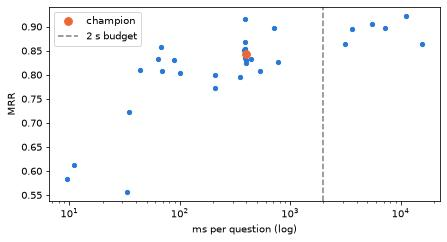

In [6]:
chosen = json.loads((GRID / "champion.json").read_text(encoding="utf-8"))
print(
    "rule:",
    {k: chosen["selection"][k] for k in ("metric", "latency_budget_ms", "corpus", "servable_only")},
)
for role in ("champion", "challenger"):
    c = chosen[role]
    print(f"{role}: {c['config']}  MRR {c['mrr']:.3f}  {c['ms_per_question']:.0f} ms / question")
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(grid.ms_per_question, grid.mrr, color="#2a78d6", s=18)
best = grid[grid.config == chosen["champion"]["config"]].iloc[0]
ax.scatter([best.ms_per_question], [best.mrr], color="#eb6834", s=60, label="champion")
ax.axvline(
    chosen["selection"]["latency_budget_ms"], color="grey", linestyle="--", label="2 s budget"
)
ax.set_xscale("log")
ax.set_xlabel("ms per question (log)")
ax.set_ylabel("MRR")
ax.legend()
plt.show()